In [1]:
import pandas as pd

# Importer le fichier CSV
df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")

# Afficher les 5 premières lignes
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [2]:
# Afficher le nombre de lignes et de colonnes
print("Dimensions :", df.shape)

# Afficher les informations sur les colonnes
df.info()

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(df.isnull().sum())

# Compter les doublons
print("\nNombre de doublons :", df.duplicated().sum())

Dimensions : (4340, 8)
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB

Valeurs manquantes :
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Nombre de doublons : 763


In [3]:
# Supprimer les doublons
df = df.drop_duplicates()

# Vérifier les dimensions après nettoyage
print("Dimensions après nettoyage :", df.shape)

# Vérifier qu'il ne reste aucun doublon
print("Doublons restants :", df.duplicated().sum())

Dimensions après nettoyage : (3577, 8)
Doublons restants : 0


In [4]:
# Variable cible : prix de la voiture
y = df["selling_price"]

# Variables d'entrée : caractéristiques de la voiture
X = df.drop("selling_price", axis=1)

# Vérifier les dimensions
print("Variables d'entrée :", X.shape)
print("Variable cible :", y.shape)

Variables d'entrée : (3577, 7)
Variable cible : (3577,)


In [5]:
from sklearn.model_selection import train_test_split

# Séparer 60 % pour l'entraînement et 40 % pour le reste
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42
)

# Diviser les 40 % restants en validation et test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42
)

# Afficher les dimensions
print("Entraînement :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)

Entraînement : (2146, 7)
Validation : (715, 7)
Test : (716, 7)


In [6]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identifier les colonnes contenant du texte
colonnes_cat = X.select_dtypes(include="object").columns

# Transformer le texte en nombres
preprocesseur = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), colonnes_cat)],
    remainder="passthrough"
)

# Apprendre la transformation sur l'entraînement
X_train_encoded = preprocesseur.fit_transform(X_train)

# Appliquer la même transformation à la validation et au test
X_val_encoded = preprocesseur.transform(X_val)
X_test_encoded = preprocesseur.transform(X_test)

print("Entraînement :", X_train_encoded.shape)
print("Validation :", X_val_encoded.shape)
print("Test :", X_test_encoded.shape)

Entraînement : (2146, 1112)
Validation : (715, 1112)
Test : (716, 1112)


C:\Users\HP\AppData\Local\Temp\ipykernel_15488\2744405624.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colonnes_cat = X.select_dtypes(include="object").columns


In [7]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Normaliser les données pour KNN
scaler = StandardScaler(with_mean=False)

X_train_knn = scaler.fit_transform(X_train_encoded)
X_val_knn = scaler.transform(X_val_encoded)

# Créer et entraîner le modèle KNN
modele_knn = KNeighborsRegressor(n_neighbors=5)
modele_knn.fit(X_train_knn, y_train)

# Faire les prédictions sur la validation
y_pred_knn = modele_knn.predict(X_val_knn)

# Calculer les erreurs
mae_knn = mean_absolute_error(y_val, y_pred_knn)
rmse_knn = np.sqrt(mean_squared_error(y_val, y_pred_knn))

print("KNN - MAE :", round(mae_knn, 2))
print("KNN - RMSE :", round(rmse_knn, 2))

KNN - MAE : 171414.08
KNN - RMSE : 439407.4


In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Créer le modèle Random Forest
modele_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Entraîner le modèle
modele_rf.fit(X_train_encoded, y_train)

# Faire les prédictions sur les données de validation
y_pred_rf = modele_rf.predict(X_val_encoded)

# Calculer les erreurs
mae_rf = mean_absolute_error(y_val, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_val, y_pred_rf))

# Afficher les résultats
print("Random Forest - MAE :", round(mae_rf, 2))
print("Random Forest - RMSE :", round(rmse_rf, 2))

Random Forest - MAE : 146934.78
Random Forest - RMSE : 362368.63


In [9]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Créer le modèle Arbre de décision
modele_dt = DecisionTreeRegressor(random_state=42)

# Entraîner le modèle
modele_dt.fit(X_train_encoded, y_train)

# Faire les prédictions sur les données de validation
y_pred_dt = modele_dt.predict(X_val_encoded)

# Calculer les erreurs
mae_dt = mean_absolute_error(y_val, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_val, y_pred_dt))

# Afficher les résultats
print("Arbre de décision - MAE :", round(mae_dt, 2))
print("Arbre de décision - RMSE :", round(rmse_dt, 2))

Arbre de décision - MAE : 161992.05
Arbre de décision - RMSE : 374510.24


              Modèle        MAE       RMSE
0                KNN  171414.08  439407.40
1  Arbre de décision  161992.05  374510.24
2      Random Forest  146934.78  362368.63

Meilleur modèle : Random Forest
MAE : 146934.78


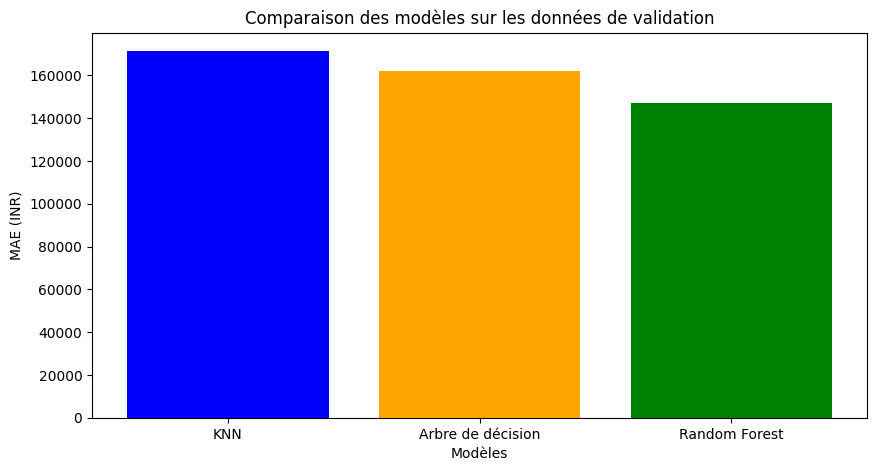

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Créer le tableau de comparaison
resultats = pd.DataFrame({
    "Modèle": ["KNN", "Arbre de décision", "Random Forest"],
    "MAE": [mae_knn, mae_dt, mae_rf],
    "RMSE": [rmse_knn, rmse_dt, rmse_rf]
})

# Afficher les résultats
print(resultats.round(2))

# Afficher le meilleur modèle selon le MAE
meilleur = resultats.loc[resultats["MAE"].idxmin()]

print("\nMeilleur modèle :", meilleur["Modèle"])
print("MAE :", round(meilleur["MAE"], 2))

# Créer un graphique
plt.figure(figsize=(10, 5))

plt.bar(
    resultats["Modèle"],
    resultats["MAE"],
    color=["blue", "orange", "green"]
)

plt.title("Comparaison des modèles sur les données de validation")
plt.xlabel("Modèles")
plt.ylabel("MAE (INR)")

plt.show()

In [11]:
import numpy as np

# Calculer l'erreur relative pour chaque voiture
erreur_relative = np.abs(
    (y_val.to_numpy() - y_pred_rf) / y_val.to_numpy()
)

# Métrique métier 1 : estimations avec une erreur de 20 % maximum
taux_estimations = np.mean(erreur_relative <= 0.20) * 100

# Métrique métier 2 : surestimations supérieures à 20 %
taux_surestimations = np.mean(
    y_pred_rf > y_val.to_numpy() * 1.20
) * 100

print("Taux d'estimations à ±20 % :", round(taux_estimations, 2), "%")
print("Taux de surestimations >20 % :", round(taux_surestimations, 2), "%")

Taux d'estimations à ±20 % : 43.36 %
Taux de surestimations >20 % : 31.19 %
